# Real-World Dataset Analysis Project: NYC Taxi Trips, March 2019
**Task 3** - AI ML Research Specialist Internship

| Part | Objective |
|---|---|
| 1 | Select a real-world dataset and understand its context |
| 2 | Explore the dataset |
| 3 | Clean and preprocess the data |
| 4 | Exploratory data analysis (Pandas, NumPy, statistics) |
| 5 | Data visualisation |
| 6 | Insights, interpretations, conclusions and recommendations |

**Reproduce:** `pip install -r requirements.txt` -> `python src/download_data.py` -> run this notebook top to bottom.

## Part 1 - Dataset selection and context

**Dataset:** NYC yellow and green taxi trips, March 2019 (6,433 trips).
**Source:** NYC Taxi & Limousine Commission (TLC) Trip Record Data, a public dataset published by the City of New York. This copy is the sample distributed in the `seaborn-data` repository (provenance and checksum in `data/SOURCE.md`).

**Why this dataset.** It is real operational data with a clear business setting (urban transport), a mix of numeric, categorical, geographic and time variables, genuine data-quality problems, and questions that matter to a taxi operator or city planner.

**Business and analytical context.** A taxi fleet earns money from fares and (for card payments) tips, and its costs and income depend on *when and where* demand occurs and how quickly vehicles move through traffic.

**Objectives (questions to answer)**
1. When and where is demand highest?
2. What determines the fare, and how well can it be predicted?
3. How do tipping behaviour and payment method vary?
4. How do yellow and green cabs differ?
5. Is there evidence of congestion (trip speed) at certain hours?

**Expected outcomes:** a cleaned dataset with documented decisions, statistically supported findings, clear visualisations and practical recommendations.

| Variable | Meaning | Type |
|---|---|---|
| pickup, dropoff | Meter start and end timestamps | datetime |
| passengers | Passenger count (driver-entered) | integer |
| distance | Trip distance in miles | numeric |
| fare | Metered fare, USD | numeric |
| tip | Tip, USD (card payments only are recorded) | numeric |
| tolls | Tolls paid, USD | numeric |
| total | Total charged: fare + tip + tolls + surcharges/taxes | numeric |
| color | Taxi type: yellow or green | categorical |
| payment | Credit card or cash | categorical |
| pickup_zone, dropoff_zone | TLC taxi zone names (194 zones) | categorical |
| pickup_borough, dropoff_borough | NYC borough of each zone | categorical |

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

SEED = 42
rng = np.random.default_rng(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
M = {}                                # key results, saved for the report

def save_fig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__)
raw = pd.read_csv(ROOT / "data" / "nyc_taxi_raw.csv")
print("Loaded raw data:", raw.shape)

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scipy 1.17.1
Loaded raw data: (6433, 14)


## Part 2 - Explore the dataset
### 2.1 Structure and data types

In [2]:
display(raw.head())
profile = pd.DataFrame({"dtype": raw.dtypes.astype(str), "non-null": raw.notna().sum(), "missing": raw.isna().sum(),
                        "missing %": (raw.isna().mean() * 100).round(2), "unique": raw.nunique()})
profile

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


,dtype,non-null,missing,missing %,unique
pickup,str,6433,0,0.00,6414
dropoff,str,6433,0,0.00,6425
passengers,int64,6433,0,0.00,7
distance,float64,6433,0,0.00,1079
fare,float64,6433,0,0.00,220
tip,float64,6433,0,0.00,489
tolls,float64,6433,0,0.00,16
total,float64,6433,0,0.00,898
color,str,6433,0,0.00,2
payment,str,6389,44,0.68,2


Note that `pickup` and `dropoff` are stored as text, not datetimes, and several text columns are categorical in nature. These are type problems to fix in Part 3.

### 2.2 Missing values and duplicates

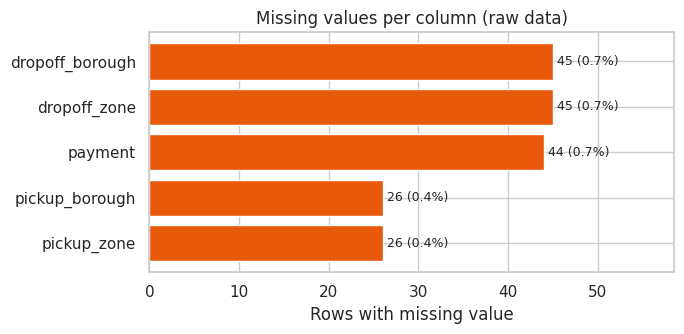

Fully duplicated rows: 0
Duplicates on pickup+dropoff+zones: 0

Are the missing values related? (rows with missing payment vs missing pickup_zone)


pickup_zone missing,False,True
payment missing,,
False,6364,25
True,43,1


Missing payment by taxi colour: {'yellow': 39, 'green': 5}


In [3]:
miss = raw.isna().sum(); miss = miss[miss > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(miss.index, miss.values, color="#E8590C")
for i, v in enumerate(miss.values): ax.text(v + 0.5, i, f"{v} ({v / len(raw):.1%})", va="center", fontsize=9)
ax.set(title="Missing values per column (raw data)", xlabel="Rows with missing value"); ax.set_xlim(0, miss.max() * 1.3)
save_fig(fig, "01_missing_values.png")

print("Fully duplicated rows:", int(raw.duplicated().sum()))
print("Duplicates on pickup+dropoff+zones:", int(raw.duplicated(subset=["pickup", "dropoff", "pickup_zone", "dropoff_zone"]).sum()))
print("\nAre the missing values related? (rows with missing payment vs missing pickup_zone)")
display(pd.crosstab(raw["payment"].isna().rename("payment missing"), raw["pickup_zone"].isna().rename("pickup_zone missing")))
print("Missing payment by taxi colour:", raw.loc[raw["payment"].isna(), "color"].value_counts().to_dict())
M.update(raw_rows=len(raw), raw_missing_cells=int(raw.isna().sum().sum()), raw_duplicates=int(raw.duplicated().sum()))

### 2.3 Distributions

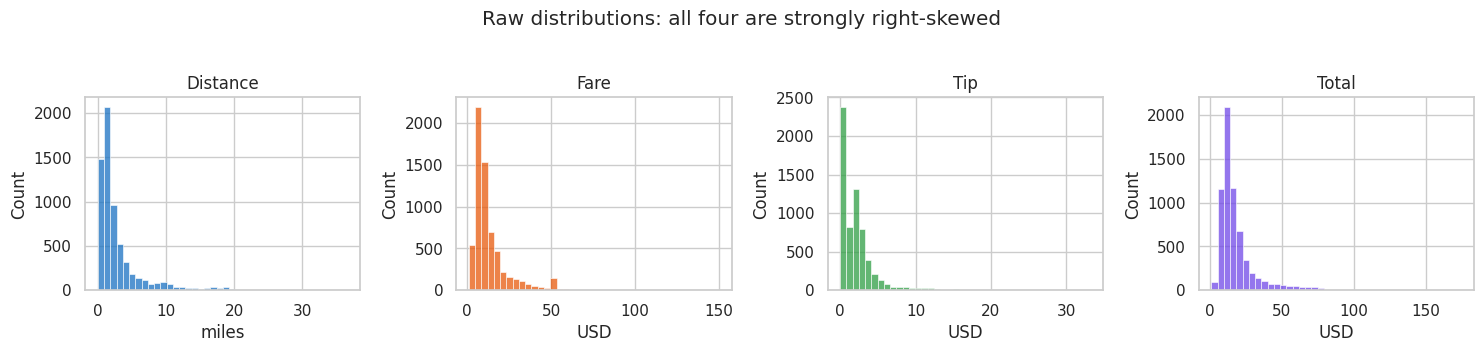

,count,mean,std,min,25%,50%,75%,max,skew
passengers,6433.0,1.54,1.20,0.0,1.00,1.00,2.00,6.00,2.36
distance,6433.0,3.02,3.83,0.0,0.98,1.64,3.21,36.70,3.01
fare,6433.0,13.09,11.55,1.0,6.50,9.50,15.00,150.00,3.22
tip,6433.0,1.98,2.45,0.0,0.00,1.70,2.80,33.20,2.67
tolls,6433.0,0.33,1.42,0.0,0.00,0.00,0.00,24.02,5.07
total,6433.0,18.52,13.82,1.3,10.80,14.16,20.30,174.82,3.09


color {'yellow': 5451, 'green': 982}
payment {'credit card': 4577, 'cash': 1812, nan: 44}
pickup_borough {'Manhattan': 5268, 'Queens': 657, 'Brooklyn': 383, 'Bronx': 99, nan: 26}


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, col, c in zip(axes, ["distance", "fare", "tip", "total"], ["#1971C2", "#E8590C", "#2F9E44", "#7048E8"]):
    sns.histplot(raw[col], bins=40, ax=ax, color=c); ax.set(title=col.capitalize(), xlabel="miles" if col == "distance" else "USD")
fig.suptitle("Raw distributions: all four are strongly right-skewed", y=1.03)
save_fig(fig, "02_raw_distributions.png")
display(raw[["passengers", "distance", "fare", "tip", "tolls", "total"]].describe().T.round(2).assign(skew=raw[["passengers", "distance", "fare", "tip", "tolls", "total"]].skew().round(2)))
for c in ["color", "payment", "pickup_borough"]:
    print(c, raw[c].value_counts(dropna=False).to_dict())

### 2.4 Relationships and consistency checks (raw data)

In [5]:
r = raw.copy(); r["pickup"] = pd.to_datetime(r["pickup"]); r["dropoff"] = pd.to_datetime(r["dropoff"])
r["duration_min"] = (r["dropoff"] - r["pickup"]).dt.total_seconds() / 60
print("Spearman correlations with fare:\n", r[["distance", "duration_min", "tip", "tolls", "passengers"]].corrwith(r["fare"], method="spearman").round(2).to_string())
print("\nPickup date range:", r["pickup"].min(), "->", r["pickup"].max())
print("Suspicious values -> passengers == 0:", int((r.passengers == 0).sum()), "| distance == 0:", int((r.distance == 0).sum()),
      "| duration <= 0:", int((r.duration_min <= 0).sum()))
print("\nMean tip by payment method (USD):", raw.groupby("payment")["tip"].mean().round(2).to_dict())
print("Share of cash trips with a recorded tip:", f"{(raw.loc[raw.payment == 'cash', 'tip'] > 0).mean():.1%}")
resid = raw["total"] - raw["fare"] - raw["tip"] - raw["tolls"]
print(f"total - (fare+tip+tolls): min {resid.min():.2f}, median {resid.median():.2f}, max {resid.max():.2f}  -> consistent surcharges/taxes, never negative")

Spearman correlations with fare:
 distance        0.93
duration_min    0.95
tip             0.31
tolls           0.37
passengers      0.00

Pickup date range: 2019-02-28 23:29:03 -> 2019-03-31 23:43:45
Suspicious values -> passengers == 0: 96 | distance == 0: 51 | duration <= 0: 6

Mean tip by payment method (USD): {'cash': 0.0, 'credit card': 2.78}
Share of cash trips with a recorded tip: 0.0%
total - (fare+tip+tolls): min 0.00, median 3.30, max 7.80  -> consistent surcharges/taxes, never negative


**What exploration revealed**
- Missing values are confined to payment type and the zone/borough fields; there are **no duplicate trips**.
- Timestamps are text; zone/borough/payment fields are categorical.
- Suspicious values: zero passengers, zero distance, non-positive durations.
- **Cash tips are always recorded as $0**: the TLC records tips for card payments only, so any tip analysis must be restricted to card trips or it will be badly biased.
- `total` = fare + tip + tolls + a small, stable amount of surcharges and taxes.

## Part 3 - Clean and preprocess
Every step is logged (rows affected + rule) so the cleaning is auditable.

| Issue | Decision |
|---|---|
| Duplicates | Check; remove if present (none found) |
| Wrong data types | Parse timestamps; convert categorical columns; integer passengers |
| Missing payment / zones / boroughs | Label `Unknown`; keep the trip (fare data is valid) |
| Passengers = 0 | Treated as unrecorded: set to missing, impute the median, keep a flag |
| Distance = 0 or duration <= 0 | Not valid completed trips: remove |
| Pickup outside March 2019 | Remove, to keep a clean one-month window |
| Impossible speed (> 80 mph) | Remove |
| Outliers in fare, distance, tip, duration | Detect with the IQR rule, inspect, **keep** if plausible, analyse robustly |

In [6]:
log = []
def note(step, n, rule): log.append({"step": step, "rows_affected": int(n), "rule": rule})

df = raw.copy()
# 1. duplicates
n = df.duplicated().sum(); df = df.drop_duplicates(); note("Duplicate rows removed", n, "drop_duplicates()")

# 2. data types
df["pickup"] = pd.to_datetime(df["pickup"]); df["dropoff"] = pd.to_datetime(df["dropoff"])
note("Timestamps parsed to datetime", len(df), "pd.to_datetime")

# 3. missing categorical values -> explicit label
for c in ["payment", "pickup_zone", "dropoff_zone", "pickup_borough", "dropoff_borough"]:
    n = df[c].isna().sum(); df[c] = df[c].fillna("Unknown")
    note(f"Missing {c} labelled Unknown", n, "fillna('Unknown'), row kept")

# 4. passengers = 0 -> unrecorded
n = (df["passengers"] == 0).sum()
df["passengers_imputed"] = df["passengers"] == 0
df["passengers"] = df["passengers"].replace(0, np.nan)
df["passengers"] = df["passengers"].fillna(df["passengers"].median()).astype(int)
note("Passengers = 0 imputed with median", n, "0 treated as unrecorded; median = " + str(int(df["passengers"].median())) + "; flag kept")

# 5. derived time features needed for validity checks
df["duration_min"] = (df["dropoff"] - df["pickup"]).dt.total_seconds() / 60
df["speed_mph"] = df["distance"] / (df["duration_min"] / 60)

# 6. invalid trips
bad_dist, bad_dur = (df["distance"] <= 0), (df["duration_min"] <= 0)
n = (bad_dist | bad_dur).sum(); df = df[~(bad_dist | bad_dur)]
note("Zero distance or non-positive duration removed", n, f"{int(bad_dist.sum())} zero-distance, {int(bad_dur.sum())} non-positive duration (overlap possible)")

# 7. outside March 2019
out = df["pickup"].dt.to_period("M") != "2019-03"
n = out.sum(); df = df[~out]; note("Pickups outside March 2019 removed", n, "keep a clean one-month window")

# 8. impossible speeds
fast = df["speed_mph"] > 80
n = fast.sum(); df = df[~fast]; note("Impossible speed (> 80 mph) removed", n, "not physically plausible in NYC")

# 9. categories
for c in ["color", "payment", "pickup_zone", "dropoff_zone", "pickup_borough", "dropoff_borough"]:
    df[c] = df[c].astype("category")
df = df.reset_index(drop=True)
print(f"rows: {len(raw)} -> {len(df)}  ({len(raw) - len(df)} removed, {(len(raw) - len(df)) / len(raw):.2%})")
pd.DataFrame(log)

rows: 6433 -> 6370  (63 removed, 0.98%)


,step,rows_affected,rule
0,Duplicate rows removed,0,drop_duplicates()
1,Timestamps parsed to datetime,6433,pd.to_datetime
2,Missing payment labelled Unknown,44,"fillna('Unknown'), row kept"
3,Missing pickup_zone labelled Unknown,26,"fillna('Unknown'), row kept"
4,Missing dropoff_zone labelled Unknown,45,"fillna('Unknown'), row kept"
5,Missing pickup_borough labelled Unknown,26,"fillna('Unknown'), row kept"
6,Missing dropoff_borough labelled Unknown,45,"fillna('Unknown'), row kept"
7,Passengers = 0 imputed with median,96,0 treated as unrecorded; median = 1; flag kept
8,Zero distance or non-positive duration removed,51,"51 zero-distance, 6 non-positive duration (ove..."
9,Pickups outside March 2019 removed,1,keep a clean one-month window


### Outlier detection (IQR rule), inspection and decision

,upper fence,outliers,outlier %,max,mean,median,5% trimmed mean
variable,,,,,,,
fare,27.8,577,9.1,150.0,13.02,9.50,11.47
distance,6.6,724,11.4,36.7,3.05,1.66,2.46
tip,7.0,265,4.2,23.2,1.97,1.70,1.66
duration_min,36.5,357,5.6,107.7,14.47,10.97,13.16
total,34.5,585,9.2,174.8,18.45,14.16,16.60


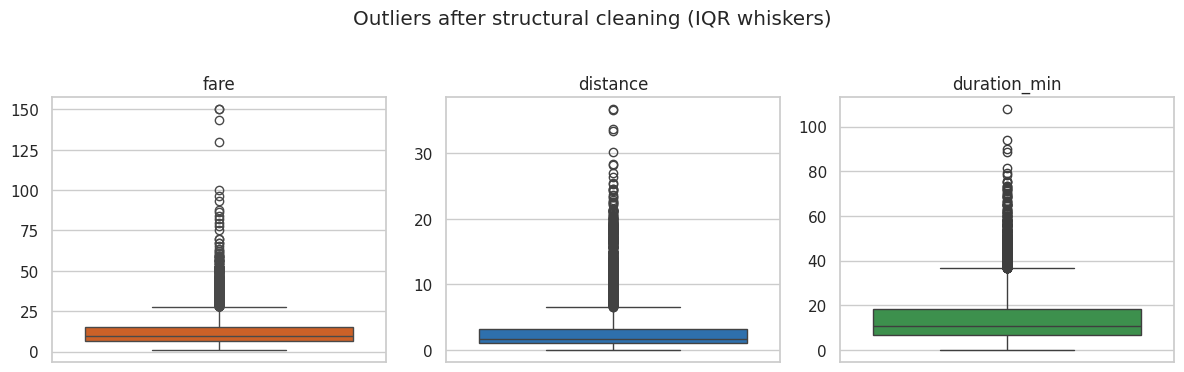

Five largest fares - are they plausible long trips?


,fare,distance,duration_min,tolls,pickup_zone,dropoff_zone
5328,150.0,36.70,64.850000,24.02,JFK Airport,JFK Airport
5606,150.0,33.46,89.883333,18.90,East Flushing,Unknown
4023,143.5,33.76,55.950000,0.00,LaGuardia Airport,Unknown
2217,130.0,26.35,46.400000,5.76,East Harlem North,Unknown
4782,100.0,10.36,25.366667,0.00,TriBeCa/Civic Center,Unknown


In [7]:
def iqr_fences(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; return q1 - 1.5 * i, q3 + 1.5 * i

rows = []
for c in ["fare", "distance", "tip", "duration_min", "total"]:
    lo, hi = iqr_fences(df[c]); n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"variable": c, "upper fence": round(hi, 1), "outliers": n_out, "outlier %": round(n_out / len(df) * 100, 1),
                 "max": round(df[c].max(), 1), "mean": round(df[c].mean(), 2), "median": round(df[c].median(), 2),
                 "5% trimmed mean": round(stats.trim_mean(df[c], .05), 2)})
outlier_table = pd.DataFrame(rows).set_index("variable"); display(outlier_table)
M["outlier_table"] = pd.DataFrame(rows).to_dict("records")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, c, col in zip(axes, ["fare", "distance", "duration_min"], ["#E8590C", "#1971C2", "#2F9E44"]):
    sns.boxplot(y=df[c], ax=ax, color=col); ax.set(title=c, ylabel="")
fig.suptitle("Outliers after structural cleaning (IQR whiskers)", y=1.03)
save_fig(fig, "03_outlier_boxplots.png")

print("Five largest fares - are they plausible long trips?")
display(df.nlargest(5, "fare")[["fare", "distance", "duration_min", "tolls", "pickup_zone", "dropoff_zone"]])

**Decision.** The high values are long, expensive trips (for example airport and out-of-borough journeys) where fare, distance and duration agree with each other, so they are **genuine, not errors**. They are kept; the analysis uses medians, trimmed means, log scales and rank-based (Spearman) statistics so a few big trips cannot distort the conclusions.

In [8]:
# derived features
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["date"]  = df["pickup"].dt.normalize()
df["hour"]  = df["pickup"].dt.hour
df["dow"]   = pd.Categorical(df["pickup"].dt.day_name(), categories=days, ordered=True)
df["is_weekend"] = df["dow"].isin(["Saturday", "Sunday"])
df["time_band"] = pd.cut(df["hour"], [-1, 5, 9, 15, 19, 23],
                         labels=["Night (00-05)", "Morning (06-09)", "Midday (10-15)", "Evening rush (16-19)", "Late evening (20-23)"])
df["surcharges"] = (df["total"] - df["fare"] - df["tip"] - df["tolls"]).round(2)
df["fare_per_mile"] = df["fare"] / df["distance"]
df["tip_pct"] = np.where(df["payment"] == "credit card", df["tip"] / df["fare"] * 100, np.nan)   # card trips only
df["airport_trip"] = df["pickup_zone"].astype(str).str.contains("Airport") | df["dropoff_zone"].astype(str).str.contains("Airport")

# validation: rules must hold or this cell fails
assert not df.duplicated().any()
assert df[["pickup", "dropoff", "distance", "fare", "total", "color", "payment", "pickup_borough"]].notna().all().all()
assert (df["distance"] > 0).all() and (df["duration_min"] > 0).all() and (df["passengers"] >= 1).all()
assert df["pickup"].dt.month.eq(3).all() and (df["surcharges"] >= 0).all()
assert df["tip_pct"].notna().sum() == (df["payment"] == "credit card").sum()
df.to_csv(ROOT / "data" / "nyc_taxi_clean.csv", index=False)
pd.DataFrame(log).to_csv(ROOT / "outputs" / "cleaning_log.csv", index=False)
M.update(clean_rows=len(df), rows_removed=int(len(raw) - len(df)), cleaning_log=log,
         outlier_counts={k: int(v) for k, v in outlier_table["outliers"].items()},
         zero_passengers=int(df["passengers_imputed"].sum()))
print("All validation checks passed | features added:", [c for c in df.columns if c not in raw.columns])

All validation checks passed | features added: ['passengers_imputed', 'duration_min', 'speed_mph', 'date', 'hour', 'dow', 'is_weekend', 'time_band', 'surcharges', 'fare_per_mile', 'tip_pct', 'airport_trip']


## Part 4 - Exploratory data analysis
### 4.1 Descriptive statistics

In [9]:
num = ["distance", "duration_min", "speed_mph", "fare", "tip", "tolls", "total", "fare_per_mile"]
desc = df[num].describe().T.round(2); desc["skew"] = df[num].skew().round(2); desc["median"] = df[num].median().round(2)
display(desc[["count", "mean", "median", "std", "min", "max", "skew"]])
M.update(mean_fare=float(df.fare.mean()), median_fare=float(df.fare.median()), mean_distance=float(df.distance.mean()),
         median_distance=float(df.distance.median()), median_duration=float(df.duration_min.median()),
         fare_skew=float(df.fare.skew()), total_revenue=float(df.total.sum()), median_speed=float(df.speed_mph.median()),
         mean_total=float(df.total.mean()))
print(f"Typical trip (median): {df.distance.median():.1f} miles, {df.duration_min.median():.0f} minutes, fare ${df.fare.median():.2f}")

,count,mean,median,std,min,max,skew
distance,6370.0,3.05,1.66,3.83,0.01,36.70,3.01
duration_min,6370.0,14.47,10.97,11.61,0.07,107.67,2.02
speed_mph,6370.0,11.49,10.07,5.88,1.22,54.17,1.75
fare,6370.0,13.02,9.50,11.24,1.00,150.00,3.16
tip,6370.0,1.97,1.70,2.37,0.00,23.19,2.31
tolls,6370.0,0.32,0.00,1.41,0.00,24.02,5.07
total,6370.0,18.45,14.16,13.43,1.30,174.82,2.99
fare_per_mile,6370.0,6.12,5.42,8.18,0.32,472.73,37.50


Typical trip (median): 1.7 miles, 11 minutes, fare $9.50


### 4.2 Demand: when and where

In [10]:
by_hour = df.groupby("hour").agg(trips=("fare", "size"), median_speed=("speed_mph", "median"))
peak_hour = int(by_hour["trips"].idxmax()); low_hour = int(by_hour["trips"].idxmin())
print(f"Busiest hour: {peak_hour}:00 ({by_hour.loc[peak_hour, 'trips']} trips) | quietest: {low_hour}:00 ({by_hour.loc[low_hour, 'trips']} trips)")
slow = by_hour["median_speed"].idxmin(); fast_h = by_hour["median_speed"].idxmax()
print(f"Slowest median speed: {slow}:00 at {by_hour.loc[slow, 'median_speed']:.1f} mph | fastest: {fast_h}:00 at {by_hour.loc[fast_h, 'median_speed']:.1f} mph")

daily = df.groupby("date").size()
wk = df.groupby(["date", "is_weekend"]).size().reset_index(name="n")
weekday_avg = wk.loc[~wk.is_weekend, "n"].mean(); weekend_avg = wk.loc[wk.is_weekend, "n"].mean()
print(f"Average trips per day: weekdays {weekday_avg:.0f} vs weekends {weekend_avg:.0f}")
# March 2019 has five Fridays, Saturdays and Sundays but only four of each other weekday, so use trips PER DAY
dow = df.groupby(["date", "dow"], observed=True).size().groupby("dow", observed=True).mean().round(0)
print("Average trips per day by weekday:", dow.astype(int).to_dict())
M["dow_avg"] = {k: float(v) for k, v in dow.items()}
M.update(day_speed=float(df.loc[df.hour.between(8, 18), "speed_mph"].median()), night_speed=float(df.loc[df.hour.between(0, 5), "speed_mph"].median()),
         late_speed=float(df.loc[df.hour.between(20, 23), "speed_mph"].median()))
print(f"Median speed: 08:00-18:59 = {M['day_speed']:.1f} mph | 20:00-23:59 = {M['late_speed']:.1f} mph | 00:00-05:59 = {M['night_speed']:.1f} mph")

zone = df["pickup_zone"].value_counts().drop("Unknown", errors="ignore").head(10)
boro = df["pickup_borough"].value_counts(normalize=True).mul(100).round(1)
print("\nPickup borough share %:", boro.to_dict())
route = (df[(df.pickup_zone != "Unknown") & (df.dropoff_zone != "Unknown")].groupby(["pickup_zone", "dropoff_zone"], observed=True).size().sort_values(ascending=False).head(5))
print("\nTop 5 routes:"); display(route.rename("trips").to_frame())
M.update(peak_hour=peak_hour, peak_hour_trips=int(by_hour.loc[peak_hour, "trips"]), low_hour=low_hour, slow_hour=int(slow), slow_speed=float(by_hour.loc[slow, "median_speed"]),
         fast_hour=int(fast_h), fast_speed=float(by_hour.loc[fast_h, "median_speed"]), weekday_avg=float(weekday_avg), weekend_avg=float(weekend_avg),
         manhattan_pickup_share=float(boro.get("Manhattan", 0)), top_zone=str(zone.index[0]), top_zone_trips=int(zone.iloc[0]),
         top_zone_share=float(zone.iloc[0] / len(df) * 100), top10_zone_share=float(zone.sum() / len(df) * 100),
         top_route=f"{route.index[0][0]} to {route.index[0][1]}", top_route_trips=int(route.iloc[0]),
         busiest_dow=str(dow.idxmax()), quietest_dow=str(dow.idxmin()))
rush = df.groupby("time_band", observed=True).agg(trips=("fare", "size"), median_speed=("speed_mph", "median"), median_fare=("fare", "median")).round(1)
display(rush)
M["time_band"] = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in rush.to_dict("index").items()}

Busiest hour: 18:00 (416 trips) | quietest: 5:00 (51 trips)
Slowest median speed: 16:00 at 8.7 mph | fastest: 5:00 at 17.0 mph
Average trips per day: weekdays 213 vs weekends 190
Average trips per day by weekday: {'Monday': 176, 'Tuesday': 204, 'Wednesday': 239, 'Thursday': 224, 'Friday': 220, 'Saturday': 206, 'Sunday': 173}
Median speed: 08:00-18:59 = 9.0 mph | 20:00-23:59 = 11.1 mph | 00:00-05:59 = 14.0 mph

Pickup borough share %: {'Manhattan': 82.4, 'Queens': 10.0, 'Brooklyn': 5.9, 'Bronx': 1.5, 'Unknown': 0.2}

Top 5 routes:


,,trips
pickup_zone,dropoff_zone,
Upper East Side North,Upper East Side North,38
Upper East Side South,Upper East Side North,30
Upper East Side North,Upper East Side South,23
Astoria,Astoria,22
Central Harlem,Central Harlem North,20


,trips,median_speed,median_fare
time_band,,,
Night (00-05),586,14.0,9.8
Morning (06-09),983,10.3,9.0
Midday (10-15),1939,9.0,9.5
Evening rush (16-19),1536,9.3,9.0
Late evening (20-23),1326,11.1,9.0


### 4.3 Fare structure: what determines the fare?

In [11]:
X = df[["distance", "duration_min"]]; y = df["fare"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.25, random_state=SEED)
lm = LinearRegression().fit(X_tr, y_tr); pred = lm.predict(X_te)
r2, mae = r2_score(y_te, pred), mean_absolute_error(y_te, pred)
print(f"fare = {lm.intercept_:.2f} + {lm.coef_[0]:.2f} x miles + {lm.coef_[1]:.2f} x minutes")
print(f"Held-out test R-squared = {r2:.3f}, mean absolute error = ${mae:.2f}")
slope, intercept = np.polyfit(df["distance"], df["fare"], 1)
print(f"Distance alone: fare = {intercept:.2f} + {slope:.2f} x miles | Spearman(fare, distance) = {df.fare.corr(df.distance, method='spearman'):.3f}")
flat = df[df["fare"] == 52]
jfk_share = (flat["pickup_zone"].astype(str).str.contains("JFK") | flat["dropoff_zone"].astype(str).str.contains("JFK")).mean() * 100
print(f"Flat-fare band: {len(flat)} trips cost exactly $52.00 | all yellow: {(flat.color == 'yellow').all()} | involve a JFK zone: {jfk_share:.0f}% | median distance {flat.distance.median():.1f} miles")
M.update(flat52_trips=int(len(flat)), flat52_jfk_share=float(jfk_share), flat52_all_yellow=bool((flat.color == "yellow").all()))
ap = df.groupby("airport_trip").agg(trips=("fare", "size"), median_fare=("fare", "median"), median_distance=("distance", "median")).round(2); display(ap)
M.update(fare_intercept=float(lm.intercept_), fare_per_mile_coef=float(lm.coef_[0]), fare_per_min_coef=float(lm.coef_[1]), fare_r2=float(r2), fare_mae=float(mae),
         spearman_fare_distance=float(df.fare.corr(df.distance, method="spearman")), airport_trips=int(ap.loc[True, "trips"]) if True in ap.index else 0,
         airport_median_fare=float(ap.loc[True, "median_fare"]) if True in ap.index else 0.0, other_median_fare=float(ap.loc[False, "median_fare"]))

fare = 2.54 + 2.09 x miles + 0.28 x minutes
Held-out test R-squared = 0.937, mean absolute error = $0.74
Distance alone: fare = 4.45 + 2.81 x miles | Spearman(fare, distance) = 0.944
Flat-fare band: 126 trips cost exactly $52.00 | all yellow: True | involve a JFK zone: 90% | median distance 18.0 miles


,trips,median_fare,median_distance
airport_trip,,,
False,5969,9.0,1.56
True,401,36.0,10.88


### 4.4 Tipping and payment (card trips only, because cash tips are not recorded)

In [12]:
card = df[df["payment"] == "credit card"]
print(f"Card trips: {len(card)} ({len(card) / len(df):.1%} of all trips)")
print(f"Tip % of fare: mean {card.tip_pct.mean():.1f}% | median {card.tip_pct.median():.1f}% | share with zero tip {(card.tip == 0).mean():.1%}")
print("\nShare of trips by payment method (%):", df["payment"].value_counts(normalize=True).mul(100).round(1).to_dict())

tb = card.groupby("time_band", observed=True)["tip_pct"].agg(["count", "mean", "median"]).round(1); display(tb)
col = card.groupby("color", observed=True)["tip_pct"].agg(["count", "mean", "median"]).round(1); display(col)
pay_col = pd.crosstab(df["color"], df["payment"], normalize="index").mul(100).round(1); display(pay_col)
db = card.groupby(pd.cut(card["distance"], [0, 1, 2, 5, 100], labels=["< 1 mi", "1-2 mi", "2-5 mi", "> 5 mi"]), observed=True)["tip_pct"].median().round(1)
print("\nMedian tip % by trip distance:", db.to_dict()); M["tip_by_distance"] = {str(k): float(v) for k, v in db.items()}
M.update(card_share=float(len(card) / len(df) * 100), tip_pct_mean=float(card.tip_pct.mean()), tip_pct_median=float(card.tip_pct.median()),
         zero_tip_share=float((card.tip == 0).mean() * 100), cash_share=float((df.payment == "cash").mean() * 100),
         tip_by_band={k: float(v) for k, v in tb["median"].items()}, tip_by_color={k: float(v) for k, v in col["median"].items()},
         cash_tip_recorded_share=float((raw.loc[raw.payment == "cash", "tip"] > 0).mean() * 100))

Card trips: 4549 (71.4% of all trips)
Tip % of fare: mean 23.9% | median 25.6% | share with zero tip 9.7%

Share of trips by payment method (%): {'credit card': 71.4, 'cash': 28.1, 'Unknown': 0.5}


,count,mean,median
time_band,,,
Night (00-05),388,24.5,25.6
Morning (06-09),729,22.2,25.0
Midday (10-15),1344,22.8,25.3
Evening rush (16-19),1101,24.8,26.3
Late evening (20-23),987,25.2,26.1


,count,mean,median
color,,,
green,565,12.9,11.8
yellow,3984,25.4,26.3


payment,Unknown,cash,credit card
color,,,
green,0.4,40.5,59.1
yellow,0.6,25.9,73.6



Median tip % by trip distance: {'< 1 mi': 31.8, '1-2 mi': 27.5, '2-5 mi': 24.6, '> 5 mi': 21.2}


### 4.5 Yellow vs green cabs

In [13]:
yg = df.groupby("color", observed=True).agg(trips=("fare", "size"), median_fare=("fare", "median"), median_distance=("distance", "median"),
                                           median_duration=("duration_min", "median"), airport_share=("airport_trip", "mean"),
                                           manhattan_pickup_share=("pickup_borough", lambda s: (s == "Manhattan").mean())).round(3)
yg["airport_share"] *= 100; yg["manhattan_pickup_share"] *= 100; display(yg.round(1))
M["color_profile"] = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in yg.round(2).to_dict("index").items()}
M["yellow_share"] = float((df.color == "yellow").mean() * 100)

,trips,median_fare,median_distance,median_duration,airport_share,manhattan_pickup_share
color,,,,,,
green,956,9.5,1.9,11.1,1.9,30.6
yellow,5414,9.5,1.6,11.0,7.1,91.5


### 4.5b Why do yellow and green tips differ? Checking for confounding
The raw gap is large, so before interpreting it I check whether location or zero-tip trips explain it.

In [14]:
zt = card.groupby("color", observed=True)["tip"].apply(lambda t: (t == 0).mean() * 100).round(1)
print("Share of card trips with a $0 tip (%):", zt.to_dict())
bor = card[card["pickup_borough"].isin(["Manhattan", "Queens", "Brooklyn", "Bronx"])]
tb_bor = bor.groupby(["pickup_borough", "color"], observed=True)["tip_pct"].agg(["count", "median"]).round(1); display(tb_bor)

man = card[card["pickup_borough"] == "Manhattan"]                                   # compare like with like
ym, gm = man.loc[man.color == "yellow", "tip_pct"], man.loc[man.color == "green", "tip_pct"]
u2, p2 = stats.mannwhitneyu(ym, gm); rb2 = 2 * u2 / (len(ym) * len(gm)) - 1
print(f"Manhattan pickups only: median tip yellow {ym.median():.1f}% vs green {gm.median():.1f}% (n = {len(ym)} vs {len(gm)}), p = {p2:.3g}, r = {rb2:.2f}")
M.update(zero_tip_green=float(zt["green"]), zero_tip_yellow=float(zt["yellow"]), tip_man_yellow=float(ym.median()), tip_man_green=float(gm.median()),
         p_tip_color_man=float(p2), rbc_tip_man=float(rb2), n_man_green=int(len(gm)))

Share of card trips with a $0 tip (%): {'green': 45.8, 'yellow': 4.6}


count  median
pickup_borough color                
Bronx          green      61     0.0
               yellow     12     0.0
Brooklyn       green     212     0.0
               yellow     45    21.0
Manhattan      green     155    22.3
               yellow   3678    26.7
Queens         green     137    11.8
               yellow    238    21.8

Manhattan pickups only: median tip yellow 26.7% vs green 22.3% (n = 3678 vs 155), p = 7.35e-16, r = 0.38


**Reading.** The large raw gap is mostly a **location and zero-tip effect**: nearly half of green-cab card trips record no tip at all, concentrated in the Bronx and Brooklyn, whereas within Manhattan the median gap narrows from about 14 to about 4 percentage points (still statistically detectable, with a smaller effect size). The data cannot separate genuine rider behaviour from differences in how tips are recorded, so the gap should not be read as "green riders tip less".

### 4.6 Correlations

In [15]:
cols = ["distance", "duration_min", "speed_mph", "passengers", "fare", "tip", "tolls", "total"]
pear = df[cols].corr(); spear = df[cols].corr(method="spearman")
print("Strongest Spearman correlations with fare:"); print(spear["fare"].drop("fare").sort_values(ascending=False).round(2).to_string())
print(f"\nPassengers vs fare (Spearman): {spear.loc['passengers', 'fare']:.2f}  -> passenger count barely matters")
M.update(spearman_fare_duration=float(spear.loc["fare", "duration_min"]), spearman_fare_passengers=float(spear.loc["fare", "passengers"]),
         spearman_fare_tolls=float(spear.loc["fare", "tolls"]), spearman_fare_tip=float(spear.loc["fare", "tip"]))

Strongest Spearman correlations with fare:
duration_min    0.97
total           0.95
distance        0.94
tolls           0.37
tip             0.30
speed_mph       0.27
passengers      0.00

Passengers vs fare (Spearman): 0.00  -> passenger count barely matters


### 4.7 Statistical tests and uncertainty

In [16]:
# (a) Tip %: yellow vs green (Mann-Whitney U, rank-biserial effect size)
y_t = card.loc[card.color == "yellow", "tip_pct"]; g_t = card.loc[card.color == "green", "tip_pct"]
u, p_mw = stats.mannwhitneyu(y_t, g_t); rbc = 2 * u / (len(y_t) * len(g_t)) - 1
print(f"(a) Tip %, yellow vs green: median {y_t.median():.1f}% vs {g_t.median():.1f}% | Mann-Whitney p = {p_mw:.3g} | rank-biserial r = {rbc:.2f}")

# (b) Does payment method depend on taxi colour? (chi-square + Cramer's V)
ct = pd.crosstab(df["color"], df["payment"]); chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"(b) Payment vs colour: chi2 = {chi2:.1f}, p = {p_chi:.3g}, Cramer's V = {v:.2f}")

# (c) Tip % across time bands (Kruskal-Wallis)
groups = [g["tip_pct"].values for _, g in card.groupby("time_band", observed=True)]
h, p_kw = stats.kruskal(*groups); print(f"(c) Tip % across time bands: H = {h:.1f}, p = {p_kw:.3g}")

# (d) Weekday vs weekend trips per day (Welch t-test on daily counts)
dn = wk.copy(); t, p_t = stats.ttest_ind(dn.loc[~dn.is_weekend, "n"], dn.loc[dn.is_weekend, "n"], equal_var=False)
print(f"(d) Daily trips weekday vs weekend: t = {t:.2f}, p = {p_t:.3g} (n = {int((~dn.is_weekend).sum())} vs {int(dn.is_weekend.sum())} days)")

# (e) Bootstrap 95% CI for the median fare per mile (NumPy)
fpm = df["fare_per_mile"].to_numpy(); boots = np.array([np.median(rng.choice(fpm, len(fpm))) for _ in range(3000)])
lo, hi = np.percentile(boots, [2.5, 97.5]); print(f"(e) Median fare per mile ${np.median(fpm):.2f}, bootstrap 95% CI [${lo:.2f}, ${hi:.2f}]")
M.update(p_tip_color=float(p_mw), rbc_tip_color=float(rbc), p_pay_color=float(p_chi), cramers_v=float(v), p_tip_band=float(p_kw),
         p_weekday=float(p_t), median_fpm=float(np.median(fpm)), fpm_lo=float(lo), fpm_hi=float(hi))

(a) Tip %, yellow vs green: median 26.3% vs 11.8% | Mann-Whitney p = 8.75e-94 | rank-biserial r = 0.53
(b) Payment vs colour: chi2 = 86.1, p = 2.03e-19, Cramer's V = 0.12


(c) Tip % across time bands: H = 33.7, p = 8.6e-07
(d) Daily trips weekday vs weekend: t = 2.59, p = 0.0162 (n = 21 vs 10 days)


(e) Median fare per mile $5.42, bootstrap 95% CI [$5.37, $5.48]


## Part 5 - Data visualisation

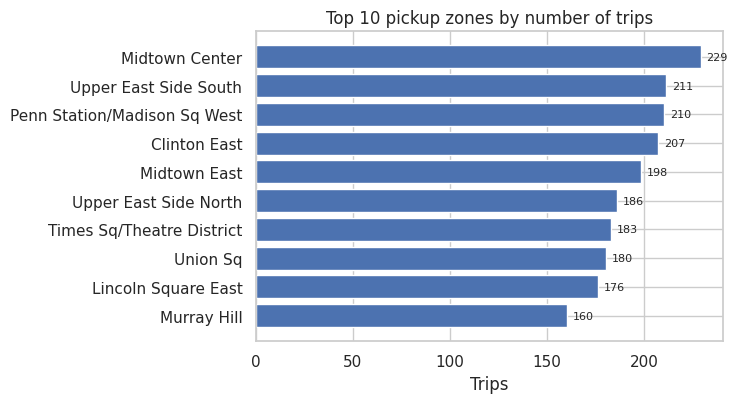

In [17]:
# 04 BAR: top pickup zones
fig, ax = plt.subplots(figsize=(7.5, 4.2))
z = zone.sort_values()
ax.barh(z.index.astype(str), z.values, color=sns.color_palette("deep")[0])
for i, val in enumerate(z.values): ax.text(val + 3, i, str(val), va="center", fontsize=8)
ax.set(title="Top 10 pickup zones by number of trips", xlabel="Trips")
save_fig(fig, "04_bar_top_pickup_zones.png")

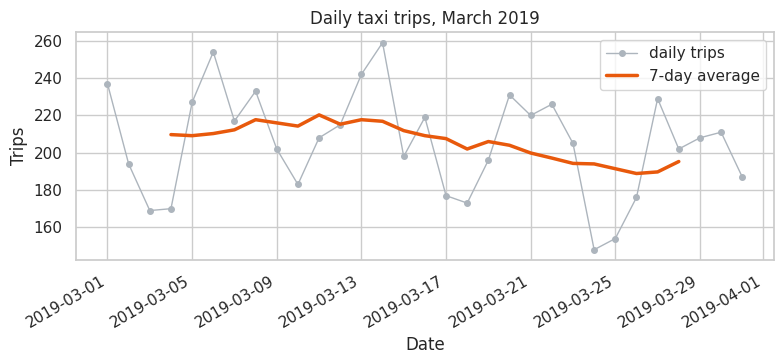

In [18]:
# 05 LINE: daily trips with 7-day rolling average
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(daily.index, daily.values, marker="o", ms=4, lw=1, color="#adb5bd", label="daily trips")
ax.plot(daily.index, daily.rolling(7, center=True).mean(), lw=2.5, color="#E8590C", label="7-day average")
ax.set(title="Daily taxi trips, March 2019", xlabel="Date", ylabel="Trips"); ax.legend(); fig.autofmt_xdate()
save_fig(fig, "05_line_daily_trips.png")

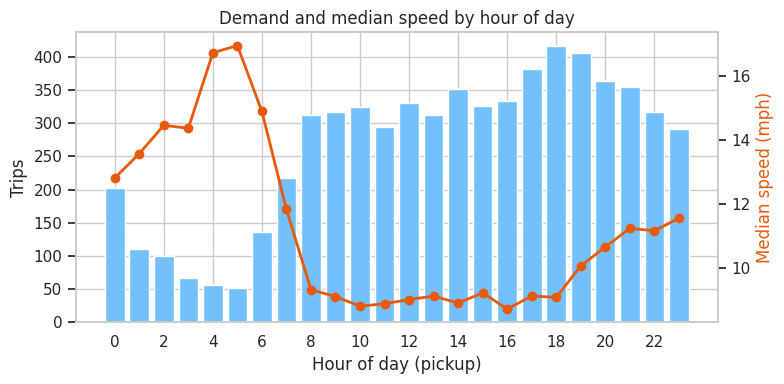

In [19]:
# 06 BAR + LINE: demand and speed by hour
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_hour.index, by_hour["trips"], color="#74c0fc", label="trips")
ax.set(title="Demand and median speed by hour of day", xlabel="Hour of day (pickup)", ylabel="Trips", xticks=range(0, 24, 2))
ax2 = ax.twinx(); ax2.plot(by_hour.index, by_hour["median_speed"], color="#E8590C", marker="o", lw=2); ax2.set_ylabel("Median speed (mph)", color="#E8590C"); ax2.grid(False)
save_fig(fig, "06_hour_demand_and_speed.png")

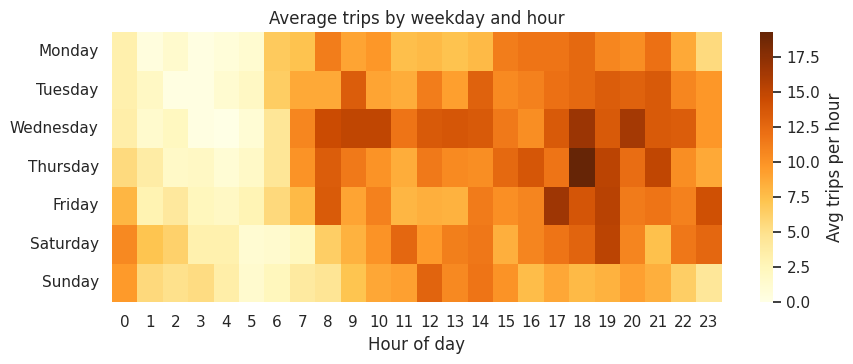

In [20]:
# 07 HEATMAP: demand by weekday and hour
heat = df.pivot_table(index="dow", columns="hour", values="fare", aggfunc="size", observed=True)
heat = heat.fillna(0).div(df.groupby("dow", observed=True)["date"].nunique(), axis=0)        # average per calendar day
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(heat, cmap="YlOrBr", ax=ax, cbar_kws={"label": "Avg trips per hour"}); ax.set(title="Average trips by weekday and hour", xlabel="Hour of day", ylabel="")
save_fig(fig, "07_heatmap_hour_weekday.png")

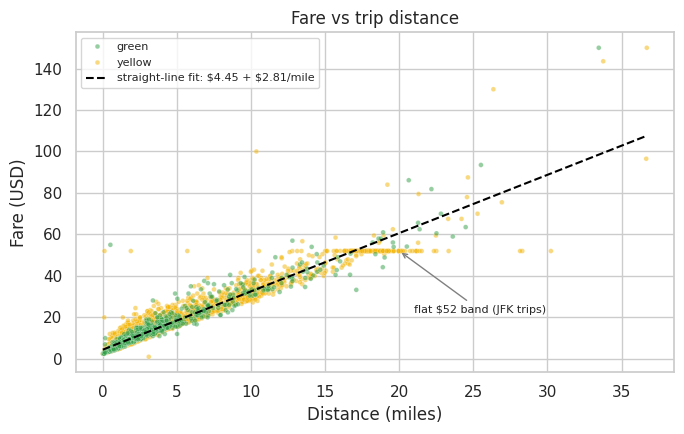

In [21]:
# 08 SCATTER: distance vs fare with fitted line
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=df, x="distance", y="fare", hue="color", palette={"yellow": "#f4b400", "green": "#2f9e44"}, s=12, alpha=.5, ax=ax)
xs = np.linspace(0, df.distance.max(), 50); ax.plot(xs, intercept + slope * xs, color="black", lw=1.5, ls="--", label="straight-line fit: " + r"\$" + f"{intercept:.2f} + " + r"\$" + f"{slope:.2f}/mile")
ax.annotate(r"flat " + r"\$" + "52 band (JFK trips)", xy=(20, 52), xytext=(21, 22), arrowprops=dict(arrowstyle="->", color="grey"), fontsize=8)
ax.set(title="Fare vs trip distance", xlabel="Distance (miles)", ylabel="Fare (USD)"); ax.legend(fontsize=8)
save_fig(fig, "08_scatter_distance_fare.png")

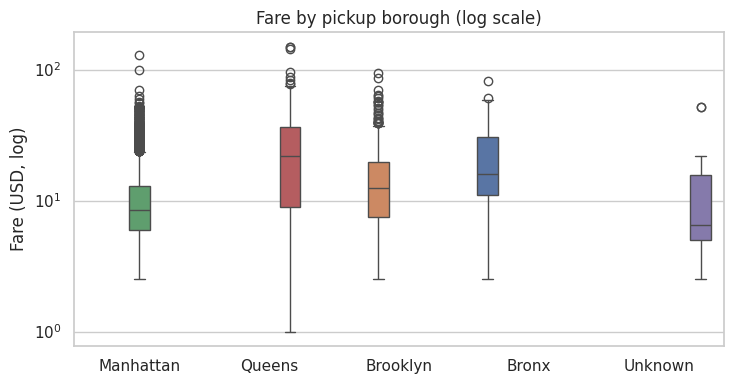

In [22]:
# 09 BOX: fare by pickup borough (log scale)
order = df["pickup_borough"].value_counts().index
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.boxplot(data=df, x="pickup_borough", y="fare", order=order, hue="pickup_borough", legend=False, ax=ax)
ax.set(yscale="log", title="Fare by pickup borough (log scale)", xlabel="", ylabel="Fare (USD, log)")
save_fig(fig, "09_box_fare_by_borough.png")

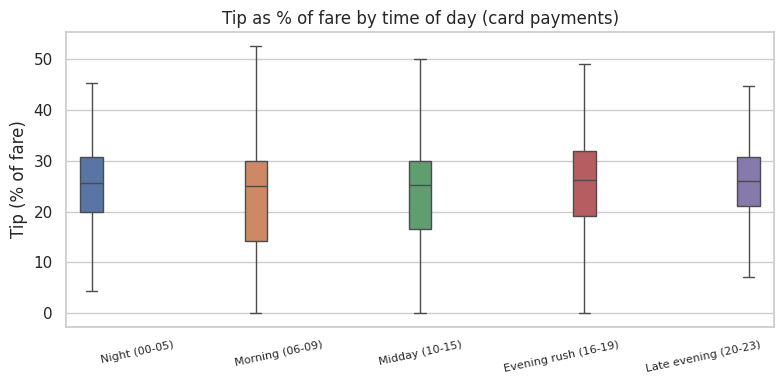

In [23]:
# 10 BOX: tip % by time band (card trips)
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=card, x="time_band", y="tip_pct", hue="time_band", legend=False, showfliers=False, ax=ax)
ax.set(title="Tip as % of fare by time of day (card payments)", xlabel="", ylabel="Tip (% of fare)"); ax.tick_params(axis="x", labelsize=8, rotation=12)
save_fig(fig, "10_box_tip_by_timeband.png")

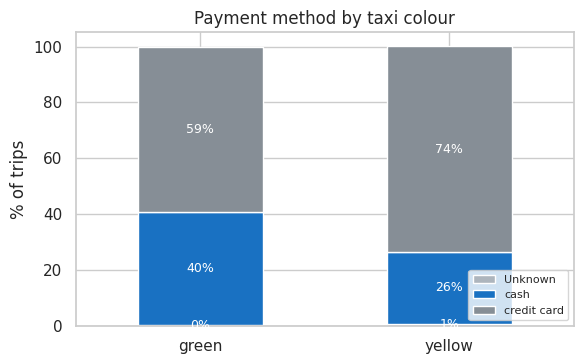

In [24]:
# 11 STACKED BAR: payment method by taxi colour
fig, ax = plt.subplots(figsize=(6, 3.8))
pay_col.plot(kind="bar", stacked=True, ax=ax, color=["#adb5bd", "#1971C2", "#868e96"][: pay_col.shape[1]], rot=0)
for c in ax.containers: ax.bar_label(c, fmt="%.0f%%", label_type="center", color="white", fontsize=9)
ax.set(title="Payment method by taxi colour", xlabel="", ylabel="% of trips"); ax.legend(title="", loc="lower right", fontsize=8)
save_fig(fig, "11_stacked_payment_by_color.png")

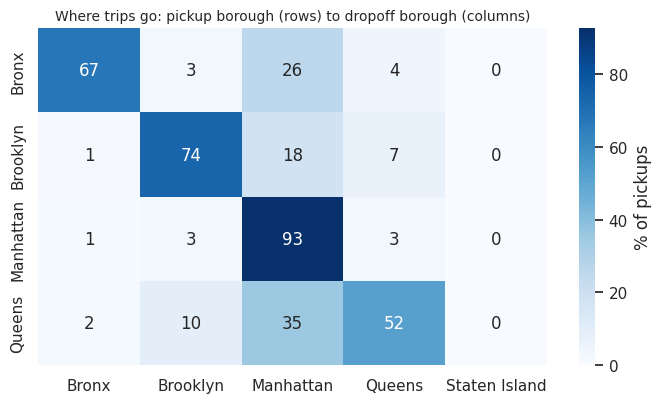

In [25]:
# 12 HEATMAP: pickup borough -> dropoff borough flows
flows = pd.crosstab(df["pickup_borough"], df["dropoff_borough"], normalize="index").mul(100)
flows = flows.drop(index="Unknown", errors="ignore").drop(columns="Unknown", errors="ignore")
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.heatmap(flows, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "% of pickups"}); ax.set(title="Where trips go: pickup borough (rows) to dropoff borough (columns)", xlabel="", ylabel="")
ax.title.set_fontsize(10); save_fig(fig, "12_heatmap_borough_flows.png")
M["manhattan_to_manhattan"] = float(flows.loc["Manhattan", "Manhattan"])

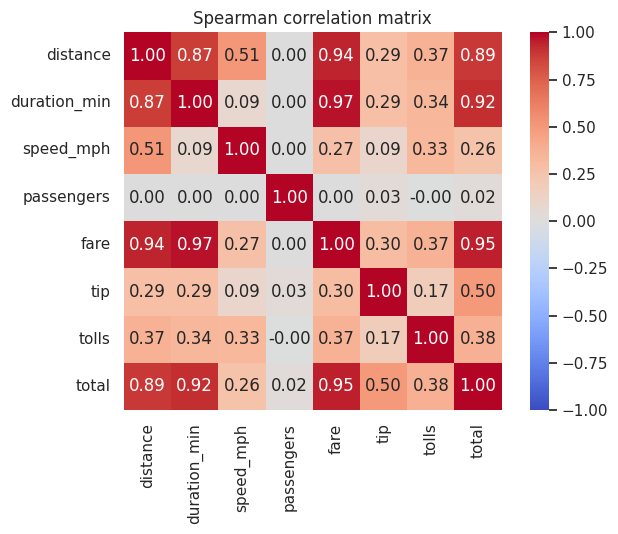

In [26]:
# 13 HEATMAP: correlation matrix (Spearman)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(spear, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=ax); ax.set_title("Spearman correlation matrix")
save_fig(fig, "13_heatmap_correlation.png")

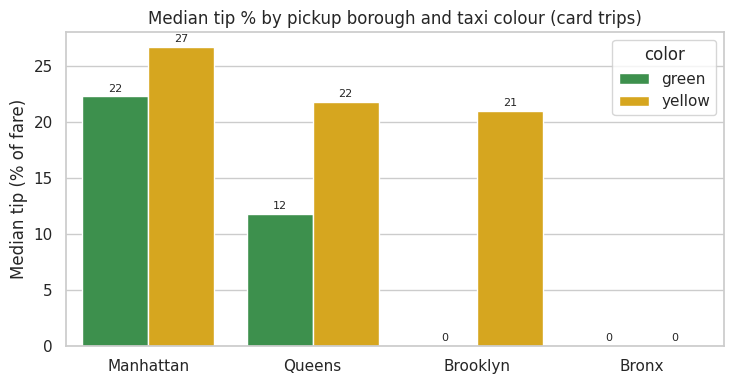

In [27]:
# 14 GROUPED BAR: tip % by borough and taxi colour (shows the confounding)
tb_plot = tb_bor.reset_index()
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.barplot(data=tb_plot, x="pickup_borough", y="median", hue="color", palette={"yellow": "#f4b400", "green": "#2f9e44"}, order=["Manhattan", "Queens", "Brooklyn", "Bronx"], ax=ax)
for c in ax.containers: ax.bar_label(c, fmt="%.0f", padding=2, fontsize=8)
ax.set(title="Median tip % by pickup borough and taxi colour (card trips)", xlabel="", ylabel="Median tip (% of fare)")
save_fig(fig, "14_bar_tip_by_borough_color.png")

## Part 6 - Insights, interpretation and recommendations

In [28]:
print(f"1. Demand timing   : peak at {M['peak_hour']}:00 ({M['peak_hour_trips']} trips); quietest at {M['low_hour']}:00. Weekdays average {M['weekday_avg']:.0f} trips/day vs {M['weekend_avg']:.0f} at weekends.")
print(f"2. Geography       : {M['manhattan_pickup_share']:.0f}% of pickups are in Manhattan; the top 10 zones hold {M['top10_zone_share']:.0f}% of trips ({M['top_zone']} is #1).")
print(f"3. Congestion      : median speed is {M['day_speed']:.1f} mph from 08:00 to 18:59, {M['late_speed']:.1f} mph from 20:00 to 23:59 and {M['night_speed']:.1f} mph overnight (slowest hour {M['slow_hour']}:00 at {M['slow_speed']:.1f} mph).")
print(f"4. Fares           : median fare ${M['median_fare']:.2f} vs mean ${M['mean_fare']:.2f} (skew {M['fare_skew']:.1f}); model fare = {M['fare_intercept']:.2f} + {M['fare_per_mile_coef']:.2f}/mile + {M['fare_per_min_coef']:.2f}/min, test R2 {M['fare_r2']:.2f}.")
print(f"5. Airports        : {M['airport_trips']} airport trips with median fare ${M['airport_median_fare']:.2f} vs ${M['other_median_fare']:.2f} for others.")
print(f"6. Tipping         : card trips are {M['card_share']:.0f}% of trips; median tip {M['tip_pct_median']:.1f}% of fare; {M['zero_tip_share']:.0f}% of card trips leave no tip. Cash tips are recorded in {M['cash_tip_recorded_share']:.0f}% of cash trips (a data limitation).")
print(f"7. Yellow vs green : raw median tip {M['tip_by_color']['yellow']:.1f}% vs {M['tip_by_color']['green']:.1f}%, but {M['zero_tip_green']:.0f}% of green card trips have a $0 tip vs {M['zero_tip_yellow']:.1f}% for yellow; in Manhattan only: {M['tip_man_yellow']:.1f}% vs {M['tip_man_green']:.1f}%.")
print(f"8. Non-finding     : passengers vs fare Spearman = {M['spearman_fare_passengers']:.2f}.")

1. Demand timing   : peak at 18:00 (416 trips); quietest at 5:00. Weekdays average 213 trips/day vs 190 at weekends.
2. Geography       : 82% of pickups are in Manhattan; the top 10 zones hold 30% of trips (Midtown Center is #1).
3. Congestion      : median speed is 9.0 mph from 08:00 to 18:59, 11.1 mph from 20:00 to 23:59 and 14.0 mph overnight (slowest hour 16:00 at 8.7 mph).
4. Fares           : median fare $9.50 vs mean $13.02 (skew 3.2); model fare = 2.54 + 2.09/mile + 0.28/min, test R2 0.94.
5. Airports        : 401 airport trips with median fare $36.00 vs $9.00 for others.
6. Tipping         : card trips are 71% of trips; median tip 25.6% of fare; 10% of card trips leave no tip. Cash tips are recorded in 0% of cash trips (a data limitation).
7. Yellow vs green : raw median tip 26.3% vs 11.8%, but 46% of green card trips have a $0 tip vs 4.6% for yellow; in Manhattan only: 26.7% vs 22.3%.
8. Non-finding     : passengers vs fare Spearman = 0.00.


### Methodology in brief
Real TLC trip records were profiled (structure, types, missingness, duplicates, distributions, relationships), cleaned with every decision logged (63 of 6,433 rows removed, under 1%), enriched with time and ratio features, and analysed with descriptive statistics, correlations, a regression model, non-parametric tests, effect sizes and a bootstrap confidence interval.

### Key findings and interpretations
1. **Demand is concentrated in time and place.** Trips peak around 18:00 and are lowest around 05:00; weekdays average more trips per day than weekends. 82% of pickups are in Manhattan and ten zones account for about 30% of trips.
2. **Traffic is slow throughout the working day, not only at rush hour.** Median speed sits near 9 mph from 08:00 to 18:59 and recovers only in the evening and overnight, so daytime trips take far longer per mile.
3. **Fares are highly predictable.** Fare is well described by a base amount plus a per-mile and a per-minute charge (held-out R-squared 0.94, mean error about $0.74), in line with a metered-fare structure. Passenger count has no relationship with fare. The scatter plot also shows a flat band at exactly $52, made up of flat-rate JFK trips, which a per-mile rule cannot capture. The largest differences come from trip type: airport trips (about 6% of trips) have a median fare around four times higher.
4. **Averages mislead for fares.** The mean fare is well above the median because a few long trips stretch the right tail; the median describes a typical trip better.
5. **Tipping must be analysed on card trips only.** Cash tips are never recorded, so including them would badly understate tipping. On card trips the median tip is about a quarter of the fare, shorter trips attract a higher tip percentage, and time of day is statistically significant but practically tiny.
6. **The yellow versus green tip gap is not what it first appears.** It is largely driven by green cabs' many zero-tip card trips outside Manhattan; within Manhattan the median difference narrows from about 14 to about 4 points, though it remains statistically detectable. This is a reminder to check for confounding before reporting a headline gap.

### Conclusions
Taxi activity in this sample is a Manhattan, daytime and evening phenomenon with slow, steady traffic; fares follow a simple distance-and-time rule; and tip analyses are only trustworthy when restricted to card payments and compared like with like.

### Potential recommendations
1. **Match supply to demand:** concentrate vehicle availability in the top Manhattan zones and in the 16:00-19:00 peak, and plan shifts around the low-demand early-morning trough.
2. **Plan for slow daytime traffic:** use time-of-day aware trip-time estimates, since speed rather than distance drives duration.
3. **Target airport trips:** a small share of trips with a much higher fare.
4. **Improve data capture:** record cash tips, validate passenger counts, and flag zero-distance trips at source.
5. **Estimate fares with distance and time** (plus tolls and airport flags to improve it further).

### Limitations
- One month (March 2019, before the pandemic) and a sample of about 6,400 trips, so route- and zone-level results are noisy and may not generalise to other periods.
- Each weekday occurs only four or five times, so day-of-week conclusions are tentative.
- Cash tips are unrecorded; the yellow-green difference cannot be separated from recording differences.
- Tests show association, not causation. Weather, events and traffic incidents were not available.

In [29]:
(ROOT / "outputs" / "key_metrics.json").write_text(json.dumps(M, indent=2, default=float))
print("Saved outputs/key_metrics.json and cleaned dataset")

Saved outputs/key_metrics.json and cleaned dataset
